# Chapitre 2 - Exercices 2.1 à 2.5

Ce notebook traite les cinq premiers exercices du chapitre 2, centrés sur le choix
entre modèles relationnel et document :

- **2.1** : choisir un modèle de données pour cinq applications (raisonnement) ;
- **2.2** : jointure multiple ou requêtes séparées ? Le seuil du produit cartésien
  (calcul et mesure) ;
- **2.3** : le coût d'un renommage dénormalisé et le risque d'incohérence (calcul et
  simulation) ;
- **2.4** : une relation plusieurs-à-plusieurs stockée des deux côtés, et sa
  réparation (mini-lab) ;
- **2.5** : migrer tout de suite ou à la lecture ? (calcul et simulation).

In [1]:
import json
import math
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 2.1 : choisir un modèle de données

**Énoncé.** Pour chacune des applications suivantes, proposer un modèle de données
(relationnel, document, graphe, ou hybride) et justifier le choix par la **forme des
relations** et les **requêtes dominantes**. Signaler le principal piège du modèle retenu.

1. Un catalogue de produits de bricolage : 40 000 références dont les attributs varient
   selon la catégorie (une perceuse a une puissance et un mandrin, une peinture une
   couleur et un rendement), affichées une par une sur une fiche produit.
2. Un logiciel de facturation : clients, factures, lignes de facture, produits, avoirs,
   paiements, avec des états comptables mensuels.
3. Un blog : chaque article a quelques étiquettes et des commentaires ; certains articles
   viraux reçoivent des dizaines de milliers de commentaires.
4. La détection de fraude : retrouver des cercles de comptes bancaires qui partagent,
   directement ou par rebonds, des numéros de téléphone, des adresses ou des appareils.
5. Un tableur collaboratif de tâches que l'on réordonne par glisser-déposer.

**Rappels.** Arbre de relations un-à-plusieurs lu d'un bloc : document (cours 1).
Plusieurs-à-un et plusieurs-à-plusieurs : normalisation, relationnel (cours 2). Données
hétérogènes : schéma à la lecture (cours 3). Relations nombreuses et chemins de longueur
variable : graphe (cours 4). Sections *Relational Versus Document Databases Today* et *Graph-Like Data Models*.

**Solution.**

*1. Catalogue* : **document**, ou colonne JSON dans une table relationnelle (hybride). Les
attributs sont hétérogènes (schéma à la lecture), chaque fiche est lue d'un bloc
(localité). Les champs communs (référence, prix, catégorie, stock) gagnent à être des
colonnes indexées. *Piège* : les filtres par attribut (« perceuses de plus de 800 W »)
exigent des index sur des valeurs imbriquées.

*2. Facturation* : **relationnel**. Les relations plusieurs-à-un (ligne -> produit,
facture -> client) dominent, les états mensuels sont des agrégations avec jointures, et
l'atomicité multi-enregistrements est indispensable (une facture et ses lignes ensemble).
*Piège* : dénormaliser le prix du produit dans la ligne **est ici voulu** (c'est le prix
historique au moment de la vente) : tout n'est pas à normaliser.

*3. Blog* : **document** pour l'article et ses étiquettes (arbre un-à-peu), mais les
commentaires dans une **collection séparée** référencée par l'identifiant de l'article :
des dizaines de milliers de commentaires feraient un document énorme, réécrit à chaque
ajout (cours 1, section 5).

*4. Fraude* : **graphe**. Comptes, téléphones, adresses, appareils sont des sommets ;
« utilise » est une arête ; un cercle est une **composante connexe**, de profondeur
inconnue à l'avance : c'est un parcours de longueur variable (`*0..` en Cypher, `WITH
RECURSIVE` en SQL).

*5. Liste réordonnable* : **document** (un tableau JSON garde l'ordre), ou relationnel avec
une astuce de tri (renumérotation, liste chaînée). *Piège* :
les modifications concurrentes de l'ordre par plusieurs utilisateurs.

**Vérification expérimentale** du cas 4 : générons 3 000 comptes qui partagent au hasard
des téléphones et des adresses, plantons un cercle de fraude (12 comptes reliés en chaîne
par des attributs partagés), et retrouvons-le comme composante connexe avec le
`PropertyGraph` du cours 4.

composante de acc100 : 14 comptes ; contient tout le cercle planté : True


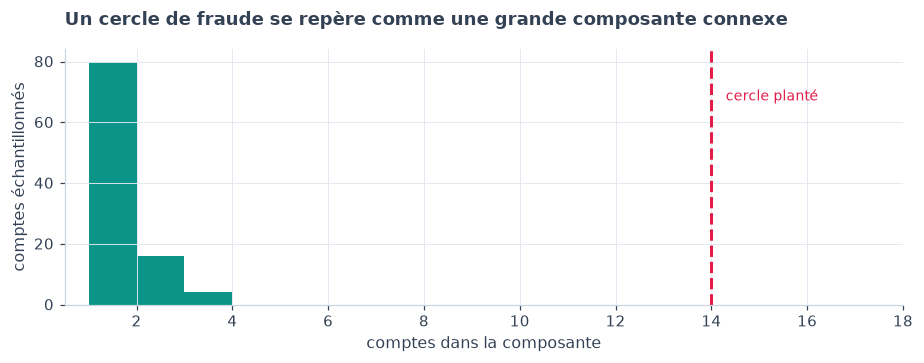

In [2]:
g = dm.PropertyGraph()
for a in range(3000):
    g.add_vertex(f"acc{a}", "Compte", name=f"acc{a}")
attrs = [f"tel{i}" for i in range(30_000)] + [f"adr{i}" for i in range(30_000)]
for a in attrs:
    g.add_vertex(a, "Attribut", name=a)
for a in range(3000):                                      # chaque compte : 1 téléphone et 1 adresse
    g.add_edge(f"acc{a}", f"tel{rng.integers(30_000)}", "UTILISE")
    g.add_edge(f"acc{a}", f"adr{rng.integers(30_000)}", "UTILISE")
cercle = [f"acc{a}" for a in range(100, 112)]
for k in range(len(cercle) - 1):                          # chaîne : chaque compte partage un appareil avec le suivant
    g.add_vertex(f"app{k}", "Attribut", name=f"app{k}")
    g.add_edge(cercle[k], f"app{k}", "UTILISE"); g.add_edge(cercle[k + 1], f"app{k}", "UTILISE")

def composante(g, v):
    """Parcours en largeur sur les arêtes UTILISE, dans les deux sens."""
    seen, front = {v}, [v]
    while front:
        nxt = []
        for x in front:
            for y in g.out(x, "UTILISE") + g.inn(x, "UTILISE"):
                if y not in seen:
                    seen.add(y); nxt.append(y)
        front = nxt
    return {x for x in seen if g.label(x) == "Compte"}

tailles = sorted((len(composante(g, f"acc{a}")) for a in range(0, 3000, 30)), reverse=True)
comp = composante(g, "acc100")
print(f"composante de acc100 : {len(comp)} comptes ; contient tout le cercle planté : {set(cercle) <= comp}")
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.hist(tailles, bins=range(1, max(tailles) + 2), color=TEAL)
ax.axvline(len(comp), color=ROSE, ls="--"); ax.text(len(comp) + 0.3, ax.get_ylim()[1] * 0.8, "cercle planté", color=ROSE, fontsize=9)
ax.set_xlim(0.5, len(comp) + 4)
ax.set_xlabel("comptes dans la composante"); ax.set_ylabel("comptes échantillonnés")
ax.set_title("Un cercle de fraude se repère comme une grande composante connexe")
plt.tight_layout(); plt.show()

Les comptes ordinaires forment de petites composantes (quelques comptes qui partagent par
hasard un téléphone ou une adresse) ; le cercle planté ressort nettement. La requête
« tous les comptes reliés à acc100 par un nombre quelconque de rebonds » est triviale en
graphe, pénible dans les autres modèles.

> **À retenir.** On choisit un modèle d'après la forme des relations et les requêtes
> dominantes : arbre lu d'un bloc -> document ; plusieurs-à-un et agrégats -> relationnel ;
> connexions arbitraires et chemins de longueur variable -> graphe. Les hybrides sont
> souvent la bonne réponse.